# Phân tích và trực quan hóa trải nghiệm khách hàng Olist

Notebook phân tích Python và trực quan hóa thành một luồng cho tám câu hỏi. Mỗi phần lần lượt trình bày bảng, kết quả phân tích, nhận xét và lựa chọn bảng dùng để vẽ, một cell trực quan hóa, rồi nhận xét biểu đồ. Phần kết luận tổng nằm cuối notebook.

### Mục tiêu phân tích
- **Câu 1:** Đánh giá phân bố review score và mức độ mất cân bằng giữa các nhóm điểm.
- **Câu 2:** So sánh mức hài lòng giữa đơn giao trễ và đơn giao đúng hạn.
- **Câu 3:** Xác định mức độ giao trễ liên quan như thế nào đến review score.
- **Câu 4:** Khảo sát mối liên hệ giữa phí vận chuyển, tỷ lệ phí trên giá hàng và review score; xem xét tương quan với các đặc trưng vận hành.
- **Câu 5:** Đánh giá mối liên hệ giữa độ phức tạp đơn hàng và review score.
- **Câu 6:** So sánh review score theo phương thức thanh toán và số kỳ trả góp.
- **Câu 7:** Theo dõi xu hướng review score theo tháng đặt hàng.
- **Câu 8:** So sánh mức hài lòng giữa các bang khách hàng.

Dữ liệu lấy từ view `v_review_order_features`, với một dòng cho mỗi đơn hàng có review. Các kết quả là mô tả mối liên hệ, không chứng minh quan hệ nhân quả. Điểm thấp được định nghĩa là 1–2 sao; khi đánh giá mô hình, cần phân biệt biến có sẵn lúc đặt hàng với biến chỉ biết sau giao hàng để tránh rò rỉ dữ liệu.

In [22]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats


def find_project_root(start_dir: Path) -> Path:
    for candidate in (start_dir, *start_dir.parents):
        if (
            (candidate / "data" / "olist.db").is_file()
            and (candidate / "sql" / "03_queries.sql").is_file()
            and (candidate / "Notebooks").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        f"Không tìm thấy thư mục gốc dự án từ {start_dir}. "
        "Hãy chạy scripts/database/build_db.py trước để tạo data/olist.db."
    )


BASE_DIR = find_project_root(Path.cwd().resolve())
DB_PATH = BASE_DIR / "data" / "olist.db"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(filename: str) -> None:
    plt.gcf().savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")


def format_p_value(p_value: float) -> str:
    return "<0.001" if p_value < 0.001 else f"{p_value:.3g}"

with sqlite3.connect(DB_PATH) as conn:
    available_views = {
        row[0]
        for row in conn.execute(
            "SELECT name FROM sqlite_master WHERE type = 'view'"
        )
    }
    if "v_review_order_features" not in available_views:
        raise RuntimeError(
            "Database chưa có view v_review_order_features. "
            "Hãy chạy scripts/database/build_db.py để dựng lại database."
        )
    review_orders = pd.read_sql_query(
        "SELECT * FROM v_review_order_features ORDER BY purchase_year_month, order_id",
        conn,
    )

review_orders["is_late"] = review_orders["is_late"].astype(bool)
review_orders["review_score"] = review_orders["review_score"].astype(int)
review_orders["low_score"] = review_orders["review_score"] <= 2
review_orders["positive_review"] = review_orders["review_score"] >= 4
review_orders["purchase_year_month"] = pd.to_datetime(
    review_orders["purchase_year_month"], format="%Y-%m"
)
ALPHA = 0.05
print(f"Database: {DB_PATH}")
print(f"Đơn hàng có review trong view SQL: {len(review_orders):,}")
print("Thang điểm review:", sorted(review_orders["review_score"].unique()))


Database: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\data\olist.db
Đơn hàng có review trong view SQL: 95,329
Thang điểm review: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## Câu 1 — Phân bố và mất cân bằng review score

Đếm số đơn và tỷ lệ của từng mức 1–5 sao để kiểm tra phân bố nhãn và xác định nhu cầu theo dõi nhóm review thấp.

In [23]:
q01 = (
    review_orders.groupby("review_score").size()
    .reindex(range(1, 6), fill_value=0)
    .rename("order_count")
    .to_frame()
)
q01["percentage"] = q01["order_count"] / q01["order_count"].sum() * 100
q01["percentage"] = q01["percentage"].round(2)
display(q01)

,order_count,percentage
review_score,,
1,9277,9.73
2,2900,3.04
3,7865,8.25
4,18807,19.73
5,56480,59.25


**Nhận xét phân tích và chọn bảng vẽ:** Điểm trung bình chung là **4,16/5**; 5 sao chiếm **59,25%** (56.480 đơn), còn nhóm 1–2 sao chiếm **12,77%**. Dùng bảng `q01`, cụ thể là số đơn và tỷ lệ theo từng mức sao, để vẽ một biểu đồ cột thể hiện đồng thời tỷ trọng từng lớp.

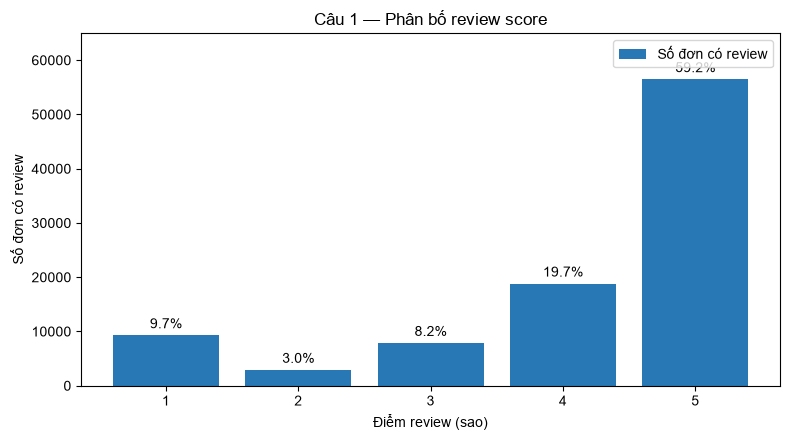

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(q01.index.astype(str), q01["order_count"], color="#2878B5", label="Số đơn có review")
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in q01["percentage"]], padding=3)
ax.set(title="Câu 1 — Phân bố review score", xlabel="Điểm review (sao)", ylabel="Số đơn có review")
ax.legend(loc="upper right")
ax.margins(y=0.15)
fig.tight_layout()
save_figure("04_01_review_score_distribution.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Phân bố nghiêng về điểm cao: 5 sao chiếm 59,25%, nhưng nhóm 1–2 sao vẫn chiếm 12,77% số đơn có review. Vì vậy, điểm trung bình chung 4,16/5 không phản ánh đầy đủ quy mô khách hàng không hài lòng. Olist cần theo dõi riêng nhóm điểm thấp và dùng thước đo phù hợp với nhãn mất cân bằng khi xây dựng cảnh báo sớm.

## Câu 2 — Giao trễ và giao đúng hạn liên quan đến review thế nào?

So sánh điểm trung bình, tỷ lệ review thấp (≤2 sao), review tích cực (≥4 sao) và cỡ mẫu giữa nhóm giao trễ với nhóm giao đúng hạn/sớm.

In [25]:
q02 = review_orders.groupby("is_late").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
).rename(index={False: "Đúng hạn hoặc sớm", True: "Giao trễ"})
q02[["positive_pct", "low_score_pct"]] *= 100
q02 = q02.round(2)
display(q02)

,order_count,avg_review_score,positive_pct,low_score_pct
is_late,,,,
Đúng hạn hoặc sớm,88978,4.29,82.71,9.23
Giao trễ,6351,2.27,26.72,62.37


**Nhận xét phân tích và chọn bảng vẽ:** Nhóm giao trễ có điểm trung bình **2,27**, thấp hơn nhóm đúng hạn/sớm (**4,29**); tỷ lệ review thấp lần lượt là **62,37%** và **9,23%**. Chọn bảng `q02` vì bảng có cả điểm trung bình, tỷ lệ review tích cực/thấp và số đơn; vẽ hai góc nhìn trong cùng một hình để không bỏ qua quy mô mẫu.

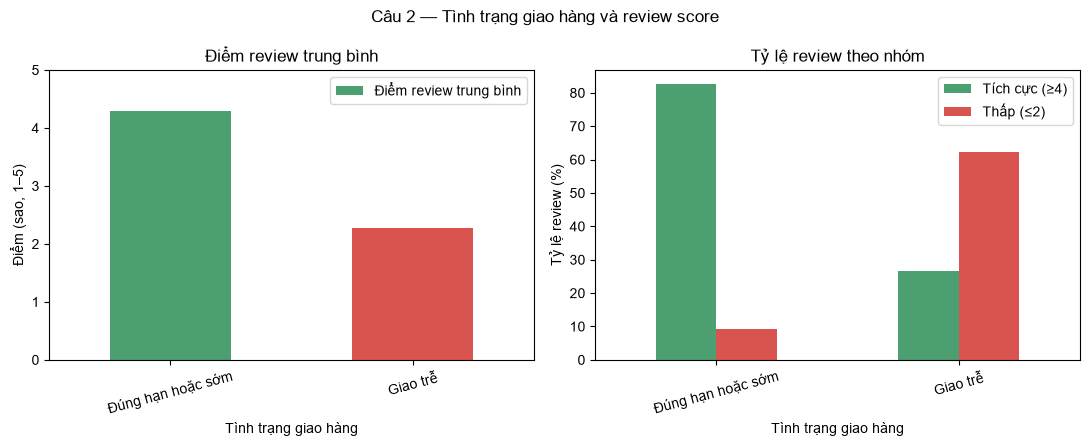

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
q02["avg_review_score"].plot(kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"], label="Điểm review trung bình")
axes[0].set(title="Điểm review trung bình", ylabel="Điểm (sao, 1–5)", xlabel="Tình trạng giao hàng", ylim=(0, 5))
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(loc="upper right")
q02[["positive_pct", "low_score_pct"]].plot(kind="bar", ax=axes[1], color=["#4C9F70", "#D9534F"])
axes[1].set(title="Tỷ lệ review theo nhóm", ylabel="Tỷ lệ review (%)", xlabel="Tình trạng giao hàng")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(["Tích cực (≥4)", "Thấp (≤2)"])
fig.suptitle("Câu 2 — Tình trạng giao hàng và review score")
fig.tight_layout()
save_figure("04_02_late_vs_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Đơn giao trễ có điểm trung bình 2,27/5 và tỷ lệ review thấp 62,37%, so với 4,29/5 và 9,23% ở nhóm giao đúng hạn hoặc sớm. Chênh lệch lớn cho thấy tình trạng giao hàng là tín hiệu vận hành đáng ưu tiên theo dõi, dù đây chỉ là mối liên hệ chứ không chứng minh nguyên nhân. Kết quả gắn trực tiếp với mục tiêu Chương 1: phát hiện sớm đơn có nguy cơ trải nghiệm xấu để Olist chủ động phối hợp logistics và chăm sóc khách hàng.

## Câu 3 — Mức độ giao trễ và review score

Chia `delay_days` thành bốn nhóm: sớm/đúng hạn, trễ 1–3 ngày, trễ 4–7 ngày và trễ trên 7 ngày; so sánh điểm trung bình, tỷ lệ review thấp/tích cực và số đơn.

In [27]:
delay_labels = ["Sớm hoặc đúng hạn", "Trễ 1–3 ngày", "Trễ 4–7 ngày", "Trễ trên 7 ngày"]
review_orders["delay_group"] = pd.cut(
    review_orders["delay_days"], bins=[-np.inf, 0, 3, 7, np.inf], labels=delay_labels
)
q03 = review_orders.groupby("delay_group", observed=False).agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
    positive_pct=("positive_review", "mean"),
)
q03[["low_score_pct", "positive_pct"]] *= 100
q03 = q03.round(2)
display(q03)

,order_count,avg_review_score,low_score_pct,positive_pct
delay_group,,,,
Sớm hoặc đúng hạn,88978,4.29,9.23,82.71
Trễ 1–3 ngày,1841,3.29,31.99,53.23
Trễ 4–7 ngày,1741,2.11,67.55,22.57
Trễ trên 7 ngày,2769,1.69,79.31,11.70


**Nhận xét phân tích và chọn bảng vẽ:** Điểm trung bình giảm theo mức trễ: **3,29** ở nhóm trễ 1–3 ngày, **2,11** ở nhóm trễ 4–7 ngày và **1,69** ở nhóm trễ trên 7 ngày; tỷ lệ review thấp đạt **79,31%** ở nhóm trễ trên 7 ngày. Chọn bảng `q03` và vẽ điểm trung bình theo nhóm trễ; giữ đúng thứ tự mức trễ để thể hiện xu hướng.

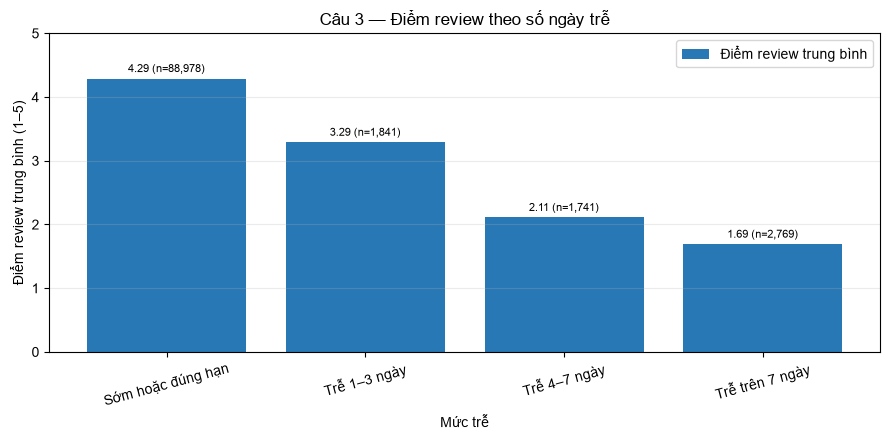

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(q03.index.astype(str), q03["avg_review_score"], color="#2878B5", label="Điểm review trung bình")
ax.bar_label(bars, labels=[f"{score:.2f} (n={count:,})" for score, count in zip(q03["avg_review_score"], q03["order_count"])], padding=3, fontsize=8)
ax.set(title="Câu 3 — Điểm review theo số ngày trễ", xlabel="Mức trễ", ylabel="Điểm review trung bình (1–5)", ylim=(0, 5))
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
fig.tight_layout()
save_figure("04_03_delay_vs_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Điểm trung bình giảm từ 3,29 ở nhóm trễ 1–3 ngày xuống 2,11 ở nhóm trễ 4–7 ngày và 1,69 ở nhóm trễ trên 7 ngày. Mức giảm theo độ trễ gợi ý rủi ro không chỉ nằm ở trạng thái trễ mà còn tăng theo số ngày chậm; các nhóm trễ có ít đơn hơn nên cần đọc cùng cỡ mẫu. Theo dõi các ngưỡng trễ giúp Olist ưu tiên can thiệp theo mức độ cấp bách thay vì xử lý mọi đơn như nhau.

### Phân tích bổ sung — phân bố độ trễ theo nhóm review


Số ngày chênh so với hạn giao dự kiến theo nhóm review


,order_count,median_delay_days,q1_delay_days,q3_delay_days
review_risk_group,,,,
Review thấp (1–2),12177,-8.0,-15.0,5.0
Review không thấp (3–5),83152,-13.0,-17.0,-8.0


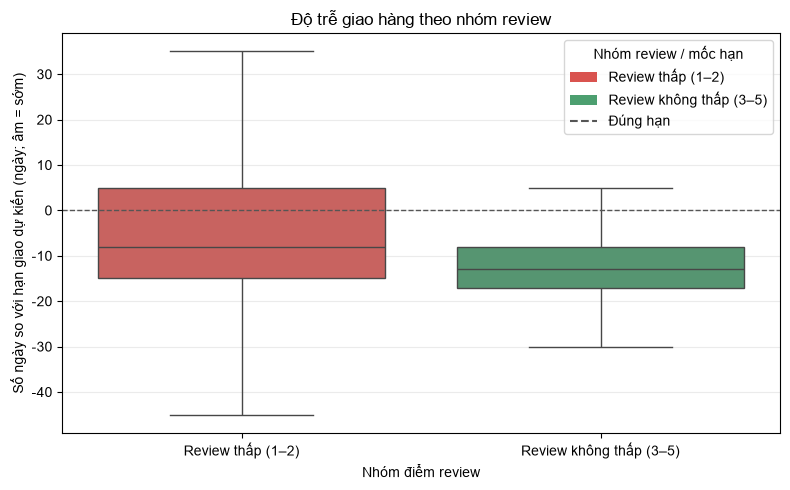

In [29]:
delay_plot_orders = review_orders.assign(
    review_risk_group=np.where(
        review_orders["review_score"].le(2), "Review thấp (1–2)", "Review không thấp (3–5)"
    )
)
risk_order = ["Review thấp (1–2)", "Review không thấp (3–5)"]
delay_by_risk = (
    delay_plot_orders.groupby("review_risk_group", observed=True)
    .agg(
        order_count=("order_id", "size"),
        median_delay_days=("delay_days", "median"),
        q1_delay_days=("delay_days", lambda values: values.quantile(0.25)),
        q3_delay_days=("delay_days", lambda values: values.quantile(0.75)),
    )
    .reindex(risk_order)
)
print("Số ngày chênh so với hạn giao dự kiến theo nhóm review")
display(delay_by_risk.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=delay_plot_orders,
    x="review_risk_group",
    y="delay_days",
    hue="review_risk_group",
    order=risk_order,
    hue_order=risk_order,
    palette={"Review thấp (1–2)": "#D9534F", "Review không thấp (3–5)": "#4C9F70"},
    dodge=False,
    showfliers=False,
    ax=ax,
)
ax.axhline(0, color="#555555", linestyle="--", linewidth=1, label="Đúng hạn")
ax.set(
    title="Độ trễ giao hàng theo nhóm review",
    xlabel="Nhóm điểm review",
    ylabel="Số ngày so với hạn giao dự kiến (ngày; âm = sớm)",
)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor="#D9534F", label="Review thấp (1–2)"),
        Patch(facecolor="#4C9F70", label="Review không thấp (3–5)"),
        Line2D([0], [0], color="#555555", linestyle="--", label="Đúng hạn"),
    ],
    title="Nhóm review / mốc hạn",
    loc="best",
)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure("04_10_delivery_delay_by_review_risk.png")
plt.show()
plt.close(fig)

**Diễn giải biểu đồ:** Boxplot so sánh số ngày chênh lệch với hạn giao dự kiến giữa hai nhóm review; giá trị âm biểu thị giao sớm, còn dương biểu thị giao trễ. Trung vị của nhóm review thấp là −8 ngày, so với −13 ngày ở nhóm review không thấp, tức nhóm thấp nhìn chung giao ít sớm hơn; độ phân tán cũng cho biết mức độ khác biệt bên trong từng nhóm. Hai phân bố vẫn chồng lấn, nên giao trễ không đồng nghĩa chắc chắn với đánh giá thấp. Biểu đồ hỗ trợ ưu tiên can thiệp sau khi giao hàng; không dùng biến trễ để dự đoán ngay lúc đặt đơn.

## Câu 4 — Phí vận chuyển, tỷ lệ phí/giá và review score

Chia đơn thành bốn quartile theo tổng phí vận chuyển và tỷ lệ phí vận chuyển/giá trị hàng. So sánh review giữa các nhóm và dùng Spearman để đo liên hệ đơn điệu; đơn có giá trị hàng bằng 0 không tham gia phân tích tỷ lệ phí/giá.

In [30]:
quartile_labels = ["Q1 thấp", "Q2", "Q3", "Q4 cao"]
for source, target in [
    ("total_freight", "freight_quartile"),
    ("freight_to_price_pct", "freight_ratio_quartile"),
]:
    review_orders[target] = pd.qcut(
        review_orders[source].rank(method="first"), q=4, labels=quartile_labels
    )
q04_freight = review_orders.groupby("freight_quartile", observed=False).agg(
    order_count=("order_id", "size"),
    avg_freight=("total_freight", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
)
valid_ratio = review_orders.dropna(subset=["freight_to_price_pct"])
q04_ratio = valid_ratio.groupby("freight_ratio_quartile", observed=False).agg(
    order_count=("order_id", "size"),
    avg_freight_ratio_pct=("freight_to_price_pct", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
)
q04_freight["low_score_pct"] *= 100
q04_ratio["low_score_pct"] *= 100
freight_rho, freight_p = stats.spearmanr(review_orders["total_freight"], review_orders["review_score"])
ratio_rho, ratio_p = stats.spearmanr(valid_ratio["freight_to_price_pct"], valid_ratio["review_score"])
print("Theo tổng phí vận chuyển:")
display(q04_freight.round(2))
print("Theo tỷ lệ phí vận chuyển/giá trị hàng:")
display(q04_ratio.round(2))
print(f"Spearman tổng phí ship và review: rho={freight_rho:.3f}, p={format_p_value(freight_p)}")
print(f"Spearman tỷ lệ phí/giá và review: rho={ratio_rho:.3f}, p={format_p_value(ratio_p)}")

Theo tổng phí vận chuyển:


,order_count,avg_freight,avg_review_score,low_score_pct
freight_quartile,,,,
Q1 thấp,23833,10.45,4.32,9.08
Q2,23832,15.46,4.19,11.74
Q3,23832,19.78,4.18,12.10
Q4 cao,23832,45.38,3.94,18.17


Theo tỷ lệ phí vận chuyển/giá trị hàng:


,order_count,avg_freight_ratio_pct,avg_review_score,low_score_pct
freight_ratio_quartile,,,,
Q1 thấp,23833,8.41,4.20,12.32
Q2,23832,17.55,4.17,12.34
Q3,23832,29.18,4.15,13.01
Q4 cao,23832,68.18,4.11,13.43


Spearman tổng phí ship và review: rho=-0.088, p=<0.001
Spearman tỷ lệ phí/giá và review: rho=-0.031, p=<0.001


**Nhận xét phân tích và chọn bảng vẽ:** Quartile phí vận chuyển cao nhất có điểm trung bình **3,94**, thấp hơn quartile thấp nhất (**4,32**); theo tỷ lệ phí/giá, chênh lệch nhỏ hơn (**4,20** so với **4,11**). Spearman lần lượt là **−0,088** và **−0,031**, tức chiều liên hệ âm nhưng yếu. Dùng hai bảng `q04_freight` và `q04_ratio` trong một hình hai panel, cùng thang điểm, để đối chiếu hai cách đo phí.

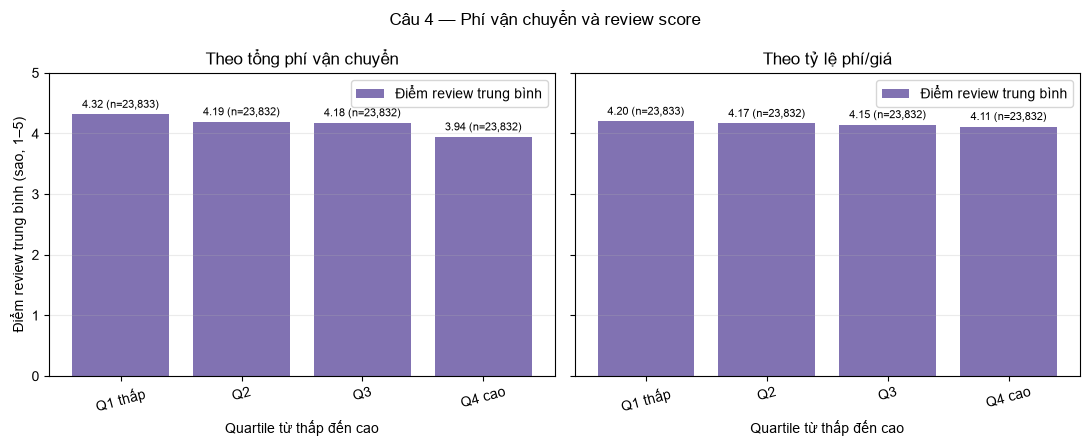

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, summary, title in [
    (axes[0], q04_freight, "Theo tổng phí vận chuyển"),
    (axes[1], q04_ratio, "Theo tỷ lệ phí/giá"),
]:
    bars = ax.bar(summary.index.astype(str), summary["avg_review_score"], color="#8172B2", label="Điểm review trung bình")
    ax.bar_label(bars, labels=[f"{score:.2f} (n={count:,})" for score, count in zip(summary["avg_review_score"], summary["order_count"])], padding=3, fontsize=8)
    ax.set(title=title, xlabel="Quartile từ thấp đến cao", ylim=(0, 5))
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Điểm review trung bình (sao, 1–5)")
fig.suptitle("Câu 4 — Phí vận chuyển và review score")
fig.tight_layout()
save_figure("04_04_freight_vs_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Điểm trung bình ở quartile phí vận chuyển cao nhất là 3,94, thấp hơn 4,32 ở quartile thấp nhất; chênh lệch theo tỷ lệ phí/giá còn nhỏ hơn. P-value nhỏ trên tập lớn không đồng nghĩa tác động thực tế mạnh, nhất là khi tương quan đơn biến với review yếu. Do đó, phí vận chuyển không nên được dùng riêng để giải thích trải nghiệm; cần xem cùng độ trễ, khu vực và độ phức tạp của đơn hàng.

### Ma trận tương quan giữa review và đặc trưng vận hành

Sử dụng tương quan Spearman vì điểm review là thang thứ bậc và các đại lượng tiền/timing có phân bố lệch. Ma trận giúp so sánh đồng thời các quan hệ với review cũng như sự phụ thuộc giữa chính các biến giải thích; hệ số nhỏ không loại trừ các ngưỡng rủi ro hoặc tương tác giữa nhóm. `delay_days` và các trường giao hàng chỉ phù hợp cho phân tích sau giao hàng, không phải dự báo tại thời điểm đặt hàng.


In [32]:
correlation_columns = [
    "review_score",
    "delay_days",
    "total_freight",
    "freight_to_price_pct",
    "item_count",
    "seller_count",
    "total_paid",
    "max_installments",
]
correlation_matrix = review_orders[correlation_columns].corr(method="spearman")
print("Ma trận tương quan Spearman (ρ)")
display(correlation_matrix.round(2))
review_correlations = correlation_matrix["review_score"].drop("review_score")
strongest_factor = review_correlations.abs().idxmax()
print(
    "Liên hệ đơn điệu mạnh nhất với review score trong các biến đã chọn: "
    f"{strongest_factor}, ρ={review_correlations[strongest_factor]:.3f}."
)


Ma trận tương quan Spearman (ρ)


,review_score,delay_days,total_freight,freight_to_price_pct,item_count,seller_count,total_paid,max_installments
review_score,1.00,-0.18,-0.09,-0.03,-0.11,-0.09,-0.04,-0.02
delay_days,-0.18,1.00,-0.16,-0.05,-0.04,-0.07,-0.06,-0.06
total_freight,-0.09,-0.16,1.00,0.10,0.38,0.14,0.57,0.23
freight_to_price_pct,-0.03,-0.05,0.10,1.00,0.08,0.02,-0.71,-0.27
item_count,-0.11,-0.04,0.38,0.08,1.00,0.35,0.22,0.06
seller_count,-0.09,-0.07,0.14,0.02,0.35,1.00,0.10,0.05
total_paid,-0.04,-0.06,0.57,-0.71,0.22,0.10,1.00,0.38
max_installments,-0.02,-0.06,0.23,-0.27,0.06,0.05,0.38,1.00


Liên hệ đơn điệu mạnh nhất với review score trong các biến đã chọn: delay_days, ρ=-0.177.


### Heatmap ma trận tương quan Spearman


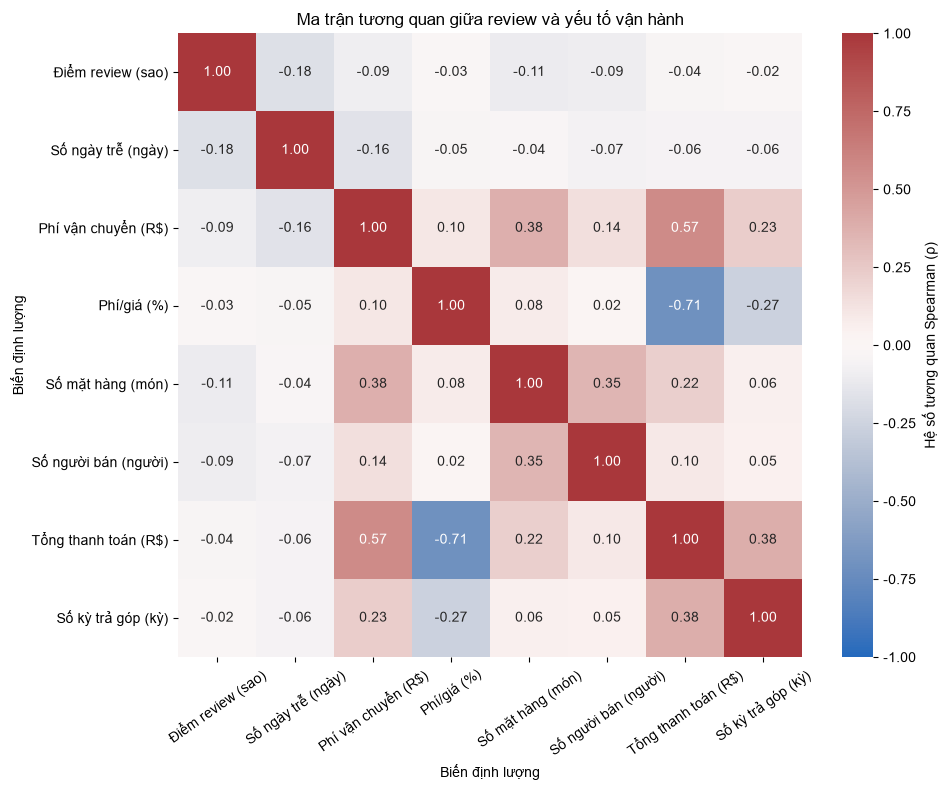

In [33]:
import seaborn as sns

correlation_labels = {
    "review_score": "Điểm review (sao)",
    "delay_days": "Số ngày trễ (ngày)",
    "total_freight": "Phí vận chuyển (R$)",
    "freight_to_price_pct": "Phí/giá (%)",
    "item_count": "Số mặt hàng (món)",
    "seller_count": "Số người bán (người)",
    "total_paid": "Tổng thanh toán (R$)",
    "max_installments": "Số kỳ trả góp (kỳ)",
}
correlation_plot = correlation_matrix.rename(index=correlation_labels, columns=correlation_labels)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlation_plot,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Hệ số tương quan Spearman (ρ)"},
    ax=ax,
)
ax.set(title="Ma trận tương quan giữa review và yếu tố vận hành", xlabel="Biến định lượng", ylabel="Biến định lượng")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
save_figure("04_09_spearman_correlation_matrix.png")
plt.show()
plt.close(fig)


**Diễn giải biểu đồ:** Ma trận cho thấy `delay_days` có tương quan Spearman âm lớn nhất với điểm review trong các biến được xét (ρ = −0,177), nhưng mức độ tương quan đơn biến chỉ thấp đến vừa. Số mặt hàng, số người bán và phí vận chuyển cũng chỉ có tương quan đơn biến yếu với điểm. Vì thế, bảng chéo theo nhóm giao hàng và độ phức tạp bổ sung tín hiệu tương tác mà một ma trận tương quan đơn lẻ không thể hiện; kết quả định hướng theo dõi logistics nhưng không chứng minh quan hệ nhân quả.

## Câu 5 — Độ phức tạp đơn hàng và review score

Đối chiếu mức đánh giá theo số mặt hàng, số sản phẩm khác nhau và số người bán trong đơn; luôn xem số lượng mẫu của từng nhóm.

In [34]:
review_orders["basket_group"] = np.select(
    [review_orders["item_count"].eq(1), review_orders["item_count"].between(2, 3)],
    ["1 mặt hàng", "2–3 mặt hàng"], default="4+ mặt hàng"
)
review_orders["product_group"] = np.select(
    [review_orders["distinct_products"].eq(1), review_orders["distinct_products"].between(2, 3)],
    ["1 sản phẩm", "2–3 sản phẩm"], default="4+ sản phẩm"
)
review_orders["seller_group"] = np.where(
    review_orders["seller_count"].eq(1), "1 người bán", "Nhiều người bán"
)
q05_tables = {}
for column, title in [
    ("basket_group", "Số mặt hàng"),
    ("product_group", "Số sản phẩm khác nhau"),
    ("seller_group", "Số người bán"),
]:
    summary = review_orders.groupby(column).agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
    )
    summary["low_score_pct"] *= 100
    q05_tables[title] = summary.round(2)
    print(title)
    display(q05_tables[title])

Số mặt hàng


,order_count,avg_review_score,low_score_pct
basket_group,,,
1 mặt hàng,85857,4.21,11.24
2–3 mặt hàng,8551,3.67,25.92
4+ mặt hàng,921,3.36,34.09


Số sản phẩm khác nhau


,order_count,avg_review_score,low_score_pct
product_group,,,
1 sản phẩm,92197,4.18,12.06
2–3 sản phẩm,3043,3.38,33.62
4+ sản phẩm,89,3.18,39.33


Số người bán


,order_count,avg_review_score,low_score_pct
seller_group,,,
1 người bán,94081,4.17,12.31
Nhiều người bán,1248,2.86,47.36


**Nhận xét phân tích và chọn bảng vẽ:** Đơn một mặt hàng có điểm trung bình **4,21**, so với **3,36** ở đơn từ 4 mặt hàng; đơn nhiều người bán có điểm **2,86** và tỷ lệ review thấp **47,36%**, so với **4,17** và **12,31%** ở đơn một người bán. Chọn ba bảng trong `q05_tables` để đặt trong một hình ba panel, tránh tạo nhiều biểu đồ riêng; nhóm từ 4 sản phẩm chỉ có 89 đơn và nhóm nhiều người bán có 1.248 đơn.

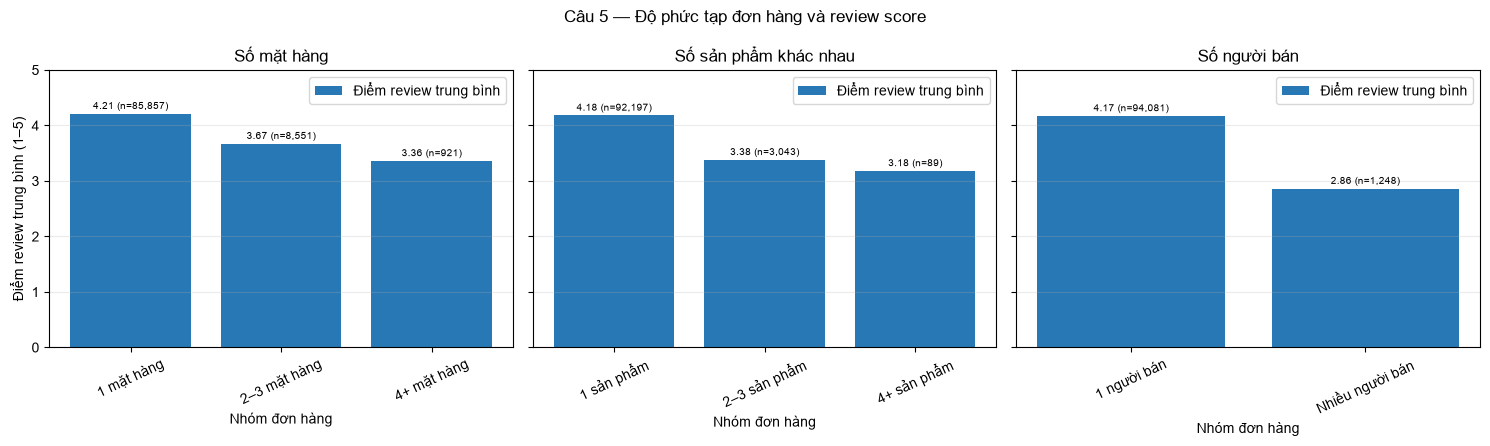

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (title, summary) in zip(axes, q05_tables.items()):
    bars = ax.bar(summary.index.astype(str), summary["avg_review_score"], color="#2878B5", label="Điểm review trung bình")
    ax.bar_label(bars, labels=[f"{score:.2f} (n={count:,})" for score, count in zip(summary["avg_review_score"], summary["order_count"])], padding=2, fontsize=7)
    ax.set(title=title, xlabel="Nhóm đơn hàng", ylim=(0, 5))
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Điểm review trung bình (1–5)")
fig.suptitle("Câu 5 — Độ phức tạp đơn hàng và review score")
fig.tight_layout()
save_figure("04_05_order_complexity_vs_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Điểm trung bình giảm từ 4,21 ở đơn một mặt hàng xuống 3,36 ở nhóm từ bốn mặt hàng; đơn có nhiều người bán có điểm trung bình 2,86 và tỷ lệ review thấp cao hơn. Điều này gợi ý rủi ro phối hợp có thể tồn tại bên cạnh bản thân thời gian giao hàng, nhưng các nhóm hiếm có cỡ mẫu nhỏ và kết quả chỉ mang tính mô tả. Olist nên theo dõi riêng đơn nhiều mặt hàng/người bán để kiểm tra khả năng phát sinh trải nghiệm phân mảnh và điều phối giao nhận phức tạp.

### Bảng chéo và nhóm đa chỉ mục — kết hợp độ trễ với số người bán

Bảng chéo dưới đây đối chiếu đồng thời mức độ giao trễ, số người bán và nhóm review; bảng chuẩn hóa cho biết tỷ lệ review thấp trong từng tổ hợp. Nhóm đa chỉ mục bổ sung quy mô mẫu, điểm trung bình và tỷ lệ review thấp để phân biệt tín hiệu có nhiều quan sát với những nhóm hiếm. Đây là phân tích mô tả có điều kiện, không chứng minh quan hệ nhân quả.


In [36]:
analysis_orders = review_orders.copy()
analysis_orders["low_score"] = analysis_orders["review_score"].le(2)
analysis_orders["delivery_band"] = pd.cut(
    analysis_orders["delay_days"],
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=["Đúng hạn/sớm", "Trễ 1–3 ngày", "Trễ 4–7 ngày", "Trễ trên 7 ngày"],
    include_lowest=True,
)
analysis_orders["seller_group"] = np.where(
    analysis_orders["seller_count"].gt(1), "Từ 2 người bán", "1 người bán"
)

cross_index = ["delivery_band", "seller_group"]
crosstab_counts = pd.crosstab(
    [analysis_orders[column] for column in cross_index],
    analysis_orders["low_score"],
    dropna=False,
).rename(columns={False: "Không thấp (đơn)", True: "Thấp (đơn)"})
crosstab_rates = (
    pd.crosstab(
        [analysis_orders[column] for column in cross_index],
        analysis_orders["low_score"],
        normalize="index",
        dropna=False,
    )
    .mul(100)
    .rename(columns={False: "Không thấp (%)", True: "Thấp (%)"})
)
print("Bảng chéo: số đơn theo tình trạng giao hàng × số người bán × nhóm review")
display(crosstab_counts)
print("Bảng chéo chuẩn hóa theo hàng: tỷ lệ review thấp/không thấp (%)")
display(crosstab_rates.round(2))

multi_index_summary = (
    analysis_orders.groupby(cross_index, observed=True)
    .agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
        avg_delay_days=("delay_days", "mean"),
    )
)
multi_index_summary["low_score_pct"] *= 100
print("Nhóm đa chỉ mục: điểm review, tỷ lệ rủi ro và quy mô mẫu")
display(multi_index_summary.round(2))

late_mask = analysis_orders["delivery_band"].ne("Đúng hạn/sớm")
low_mask = analysis_orders["low_score"]
late_share = late_mask.mean() * 100
late_share_among_low = late_mask[low_mask].mean() * 100
on_time_groups = multi_index_summary.xs("Đúng hạn/sớm", level="delivery_band")
single_seller_risk = on_time_groups.loc["1 người bán", "low_score_pct"]
multiple_seller_risk = on_time_groups.loc["Từ 2 người bán", "low_score_pct"]
print("KEY FINDINGS — các tỷ lệ được tính trực tiếp từ dữ liệu")
print(f"• Đơn giao trễ chiếm {late_share:.2f}% toàn bộ đơn có review, nhưng chiếm {late_share_among_low:.2f}% nhóm review thấp.")
print(
    "• Trong các đơn đúng hạn/sớm, tỷ lệ review thấp là "
    f"{multiple_seller_risk:.2f}% ở nhóm từ 2 người bán "
    f"(n={int(on_time_groups.loc['Từ 2 người bán', 'order_count']):,}) so với "
    f"{single_seller_risk:.2f}% ở nhóm 1 người bán "
    f"(n={int(on_time_groups.loc['1 người bán', 'order_count']):,})."
)
print("• Đây là các mối liên hệ có điều kiện, không chứng minh nguyên nhân; luôn đọc tỷ lệ cùng số mẫu.")


Bảng chéo: số đơn theo tình trạng giao hàng × số người bán × nhóm review


low_score                       Không thấp (đơn)  Thấp (đơn)
delivery_band   seller_group                                
Đúng hạn/sớm    1 người bán                80108        7634
                Từ 2 người bán               654         582
Trễ 1–3 ngày    1 người bán                 1250         585
                Từ 2 người bán                 2           4
Trễ 4–7 ngày    1 người bán                  564        1171
                Từ 2 người bán                 1           5
Trễ trên 7 ngày 1 người bán                  573        2196
                Từ 2 người bán                 0           0

Bảng chéo chuẩn hóa theo hàng: tỷ lệ review thấp/không thấp (%)


low_score                       Không thấp (%)  Thấp (%)
delivery_band   seller_group                            
Đúng hạn/sớm    1 người bán              91.30      8.70
                Từ 2 người bán           52.91     47.09
Trễ 1–3 ngày    1 người bán              68.12     31.88
                Từ 2 người bán           33.33     66.67
Trễ 4–7 ngày    1 người bán              32.51     67.49
                Từ 2 người bán           16.67     83.33
Trễ trên 7 ngày 1 người bán              20.69     79.31
                Từ 2 người bán            0.00      0.00

Nhóm đa chỉ mục: điểm review, tỷ lệ rủi ro và quy mô mẫu


order_count  avg_review_score  low_score_pct  \
delivery_band   seller_group                                                   
Đúng hạn/sớm    1 người bán           87742              4.31           8.70   
                Từ 2 người bán         1236              2.87          47.09   
Trễ 1–3 ngày    1 người bán            1835              3.30          31.88   
                Từ 2 người bán            6              2.00          66.67   
Trễ 4–7 ngày    1 người bán            1735              2.11          67.49   
                Từ 2 người bán            6              1.67          83.33   
Trễ trên 7 ngày 1 người bán            2769              1.69          79.31   

                                avg_delay_days  
delivery_band   seller_group                    
Đúng hạn/sớm    1 người bán             -13.46  
                Từ 2 người bán          -17.16  
Trễ 1–3 ngày    1 người bán               1.82  
                Từ 2 người bán            2.17  
Trễ 4–7 ngày    1 người bán               5.52  
                Từ 2 người bán            5.33  
Trễ trên 7 ngày 1 người bán              19.44

KEY FINDINGS — các tỷ lệ được tính trực tiếp từ dữ liệu
• Đơn giao trễ chiếm 6.66% toàn bộ đơn có review, nhưng chiếm 32.53% nhóm review thấp.
• Trong các đơn đúng hạn/sớm, tỷ lệ review thấp là 47.09% ở nhóm từ 2 người bán (n=1,236) so với 8.70% ở nhóm 1 người bán (n=87,742).
• Đây là các mối liên hệ có điều kiện, không chứng minh nguyên nhân; luôn đọc tỷ lệ cùng số mẫu.


## Câu 6 — Phương thức thanh toán, trả góp và review score

Theo phương thức thanh toán đầu tiên của đơn hàng và số kỳ trả góp tối đa, so sánh số đơn, điểm trung bình, tỷ lệ review thấp và tỷ lệ review tích cực.

In [37]:
q06_payment = review_orders.dropna(subset=["first_payment_type"]).groupby("first_payment_type").agg(
    order_count=("order_id", "size"),
    avg_installments=("max_installments", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
    positive_pct=("positive_review", "mean"),
).sort_values("order_count", ascending=False)
q06_payment[["low_score_pct", "positive_pct"]] *= 100
review_orders["installment_group"] = pd.cut(
    review_orders["max_installments"].fillna(0), bins=[-np.inf, 1, 3, 6, np.inf],
    labels=["1 kỳ", "2–3 kỳ", "4–6 kỳ", "7+ kỳ"]
)
q06_installments = review_orders.groupby("installment_group", observed=False).agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
)
q06_installments["low_score_pct"] *= 100
print("Theo phương thức thanh toán:")
display(q06_payment.round(2))
print("Theo số kỳ trả góp tối đa:")
display(q06_installments.round(2))

Theo phương thức thanh toán:


,order_count,avg_installments,avg_review_score,low_score_pct,positive_pct
first_payment_type,,,,,
credit_card,73385,3.5,4.16,12.84,79.02
boleto,18970,1.0,4.16,12.51,78.87
voucher,1473,1.0,4.11,14.32,76.37
debit_card,1424,1.0,4.25,10.88,81.46


Theo số kỳ trả góp tối đa:


,order_count,avg_review_score,low_score_pct
installment_group,,,
1 kỳ,46327,4.19,11.87
2–3 kỳ,21888,4.15,12.85
4–6 kỳ,15534,4.13,13.47
7+ kỳ,11580,4.08,15.31


**Nhận xét phân tích và chọn bảng vẽ:** Các phương thức phổ biến có điểm gần nhau (credit card và boleto **4,16**); debit card đạt **4,25** trên 1.424 đơn. Theo kỳ trả góp, điểm giảm nhẹ từ **4,19** (1 kỳ) xuống **4,08** (7+ kỳ). Chọn bảng `q06_payment` để vẽ một biểu đồ thanh ngang có ghi cỡ mẫu; bảng `q06_installments` vẫn được giữ để đối chiếu nhưng không tạo biểu đồ thứ hai.

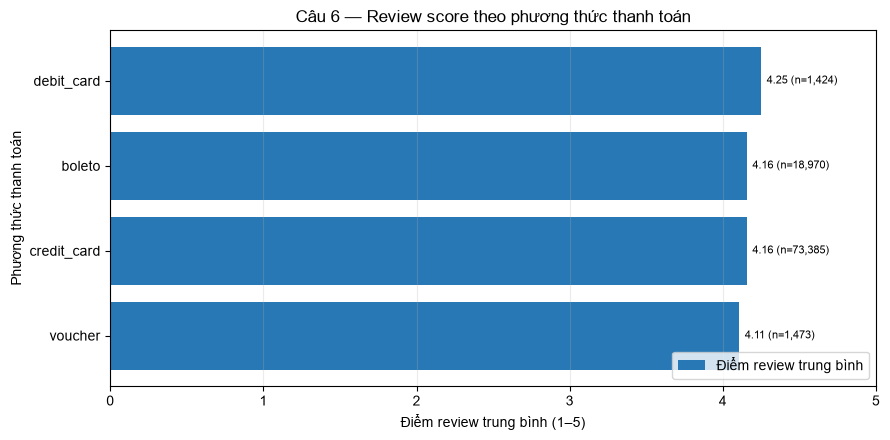

In [38]:
plot_data = q06_payment.sort_values("avg_review_score")
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_data.index.astype(str), plot_data["avg_review_score"], color="#2878B5", label="Điểm review trung bình")
ax.bar_label(bars, labels=[f"{score:.2f} (n={count:,})" for score, count in zip(plot_data["avg_review_score"], plot_data["order_count"])], padding=4, fontsize=8)
ax.set(title="Câu 6 — Review score theo phương thức thanh toán", xlabel="Điểm review trung bình (1–5)", ylabel="Phương thức thanh toán", xlim=(0, 5))
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
save_figure("04_06_payment_vs_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Các phương thức thanh toán phổ biến có điểm gần nhau, như thẻ tín dụng và boleto cùng khoảng 4,16; điểm thẻ ghi nợ 4,25 dựa trên 1.424 đơn. Chênh lệch này nhỏ hơn rõ rệt so với khác biệt giữa nhóm giao trễ và đúng hạn, còn nhóm thanh toán hiếm có ít quan sát. Vì vậy, thanh toán phù hợp làm tín hiệu bổ trợ trong phân tích và mô hình, không phải đòn bẩy vận hành chính để cải thiện hài lòng.

## Câu 7 — Xu hướng review theo tháng đặt hàng

Tổng hợp số đơn, điểm trung bình và tỷ lệ review tích cực/thấp theo tháng đặt hàng. Cỡ mẫu theo tháng giúp tránh diễn giải quá mức các giai đoạn có ít đơn.

In [39]:
q07 = review_orders.groupby("purchase_year_month").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
).sort_index()
q07[["positive_pct", "low_score_pct"]] *= 100
q07 = q07.round(2)
display(q07)

,order_count,avg_review_score,positive_pct,low_score_pct
purchase_year_month,,,,
2016-10-01,260,4.01,75.38,16.54
2016-12-01,1,5.00,100.00,0.00
2017-01-01,729,4.20,79.84,11.93
2017-02-01,1634,4.21,79.44,11.02
2017-03-01,2506,4.19,79.93,11.13
2017-04-01,2276,4.13,78.08,13.01
2017-05-01,3490,4.24,80.97,10.00
2017-06-01,3083,4.22,80.60,10.70
2017-07-01,3809,4.26,81.46,9.90


**Nhận xét phân tích và chọn bảng vẽ:** Điểm theo tháng dao động, đạt **4,32** vào 08/2017, giảm xuống **3,81** vào 03/2018 (tỷ lệ review thấp **21,09%**) rồi phục hồi lên **4,21** vào 04/2018. Tháng 12/2016 chỉ có 1 đơn. Chọn bảng `q07` để vẽ điểm trung bình cùng số lượng đơn theo tháng, nhấn mạnh cỡ mẫu và biến động xu hướng.

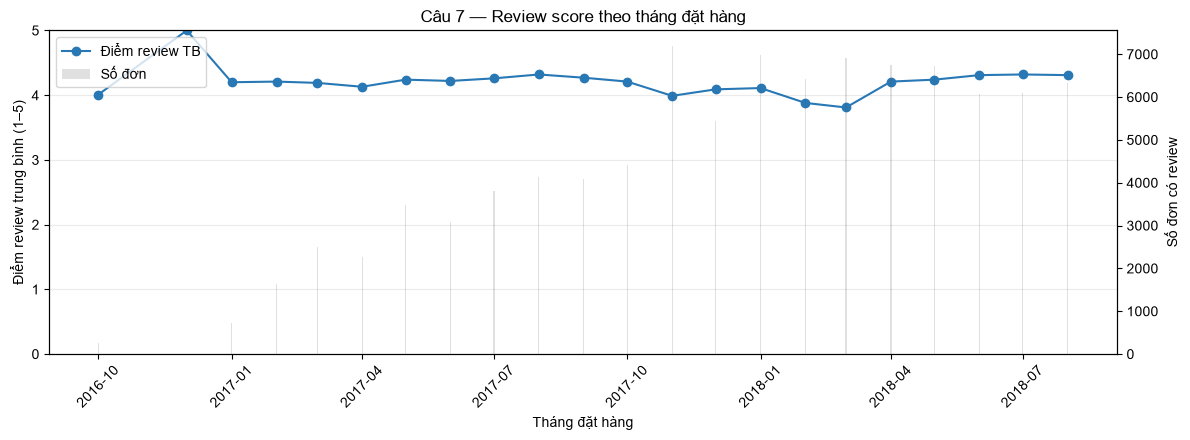

In [40]:
fig, ax_score = plt.subplots(figsize=(12, 4.5))
ax_score.plot(q07.index, q07["avg_review_score"], color="#2878B5", marker="o", label="Điểm review TB")
ax_score.set_ylabel("Điểm review trung bình (1–5)")
ax_score.set_ylim(0, 5)
ax_score.tick_params(axis="x", rotation=45)
ax_count = ax_score.twinx()
ax_count.bar(q07.index, q07["order_count"], alpha=0.18, color="#555555", label="Số đơn")
ax_count.set_ylabel("Số đơn có review")
ax_score.set_title("Câu 7 — Review score theo tháng đặt hàng")
ax_score.set_xlabel("Tháng đặt hàng")
ax_score.grid(axis="y", alpha=0.25)
line_handles, line_labels = ax_score.get_legend_handles_labels()
bar_handles, bar_labels = ax_count.get_legend_handles_labels()
ax_score.legend(line_handles + bar_handles, line_labels + bar_labels, loc="upper left")
fig.tight_layout()
save_figure("04_07_monthly_review_score.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Điểm review theo tháng dao động, đạt 4,32 vào 08/2017 rồi giảm còn 3,81 vào 03/2018, khi tỷ lệ review thấp lên 21,09%, trước khi phục hồi lên 4,21 vào tháng cuối có dữ liệu. Biến động này giúp nhận diện giai đoạn cần điều tra nhưng không xác định nguyên nhân; các tháng có ít đơn cần được xem cùng quy mô mẫu. Olist có thể dùng giám sát theo tháng để phát hiện sớm suy giảm chất lượng và đối chiếu với thay đổi vận hành theo thời gian.

## Câu 8 — Mức hài lòng theo bang khách hàng

So sánh số đơn, điểm trung bình, tỷ lệ review tích cực/thấp, tỷ lệ giao trễ và thời gian giao theo bang khách hàng; cần lưu ý cỡ mẫu giữa các bang khác nhau.

In [41]:
q08 = review_orders.groupby("customer_state").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
    late_rate_pct=("is_late", "mean"),
    avg_delivery_days=("delivery_days", "mean"),
)
q08[["positive_pct", "low_score_pct", "late_rate_pct"]] *= 100
q08 = q08.sort_values(["avg_review_score", "order_count"], ascending=[True, False]).round(2)
display(q08)
state_rho, state_p = stats.spearmanr(q08["late_rate_pct"], q08["avg_review_score"])
print(f"Spearman giữa tỷ lệ giao trễ và điểm review cấp bang: rho={state_rho:.3f}, p={format_p_value(state_p)}")
print("Tương quan trên các bang không phải kiểm định nhân quả ở cấp đơn hàng.")

,order_count,avg_review_score,positive_pct,low_score_pct,late_rate_pct,avg_delivery_days
customer_state,,,,,,
MA,706,3.82,69.97,20.11,17.28,21.43
AL,393,3.85,71.76,21.12,20.61,24.41
RR,41,3.90,68.29,14.63,12.20,29.39
SE,332,3.90,72.29,18.98,15.06,21.45
PA,924,3.92,72.40,17.86,10.82,23.63
BA,3213,3.93,72.92,16.99,11.89,19.24
CE,1272,3.94,72.80,17.14,13.68,21.22
RJ,12136,3.97,73.48,18.27,11.95,15.24
PI,470,3.99,75.11,16.17,13.62,19.48


Spearman giữa tỷ lệ giao trễ và điểm review cấp bang: rho=-0.880, p=<0.001
Tương quan trên các bang không phải kiểm định nhân quả ở cấp đơn hàng.


**Nhận xét phân tích và chọn bảng vẽ:** Spearman giữa tỷ lệ giao trễ và điểm review cấp bang là **−0,880** (`p < 0,001`): bang có giao trễ cao hơn thường có điểm thấp hơn. Ví dụ MA có tỷ lệ trễ **17,28%**, điểm **3,82** (706 đơn), trong khi SP có tỷ lệ trễ **4,44%**, điểm **4,25** (40.063 đơn). Chọn bảng `q08` để vẽ scatter: tỷ lệ trễ trên trục x, điểm trung bình trên trục y, màu biểu thị tỷ lệ review thấp và kích thước biểu thị số đơn.

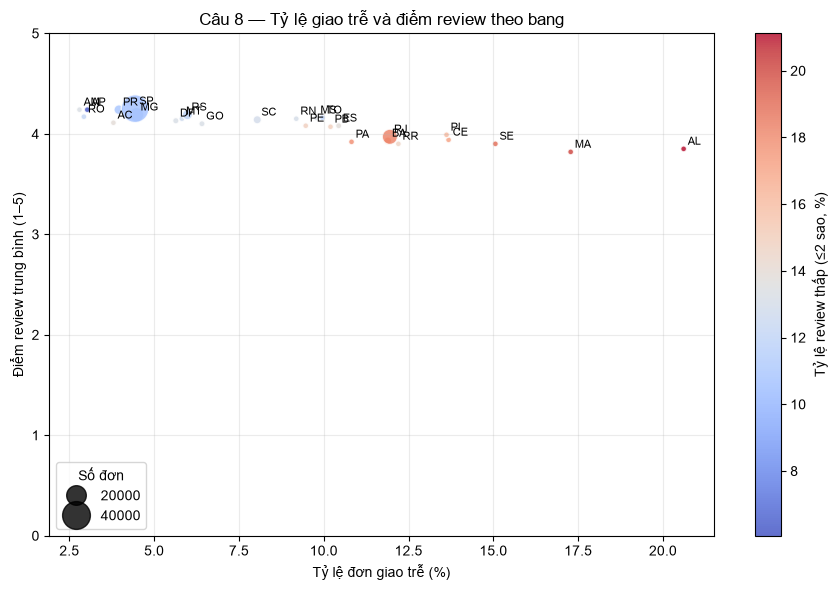

In [42]:
fig, ax = plt.subplots(figsize=(9, 6))
points = ax.scatter(
    q08["late_rate_pct"], q08["avg_review_score"],
    s=np.maximum(q08["order_count"] / 100, 18), c=q08["low_score_pct"],
    cmap="coolwarm", alpha=0.8, edgecolors="white"
)
for state, row in q08.iterrows():
    ax.annotate(state, (row["late_rate_pct"], row["avg_review_score"]),
                fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set(title="Câu 8 — Tỷ lệ giao trễ và điểm review theo bang",
       xlabel="Tỷ lệ đơn giao trễ (%)", ylabel="Điểm review trung bình (1–5)", ylim=(0, 5))
ax.grid(alpha=0.25)
fig.colorbar(points, ax=ax, label="Tỷ lệ review thấp (≤2 sao, %)")
size_handles, size_labels = points.legend_elements(
    prop="sizes", num=3, func=lambda value: value * 100, fmt="{x:.0f}"
)
ax.legend(size_handles, size_labels, title="Số đơn", loc="lower left")
fig.tight_layout()
save_figure("04_08_review_by_state.png")
plt.show()
plt.close(fig)

**Nhận xét biểu đồ:** Ở cấp bang, tỷ lệ giao trễ và điểm review có tương quan Spearman âm mạnh (ρ = −0,880; p < 0,001), cho thấy các bang trễ nhiều thường có điểm thấp hơn. Đây là quan hệ tổng hợp theo bang, không thể suy rộng trực tiếp thành quan hệ ở cấp đơn hàng hoặc xem là bằng chứng nhân quả. Kết quả giúp Olist khoanh vùng cần rà soát tuyến và đối tác logistics, đồng thời phải ưu tiên bang có đủ số đơn để tránh bị chi phối bởi mẫu nhỏ.

## Nhận xét tổng và kết luận cho bước train model tiếp theo

1. **Giao hàng là tín hiệu nổi bật nhất:** cả trạng thái giao trễ, mức độ trễ và so sánh theo bang đều đi cùng tỷ lệ review thấp hơn/điểm trung bình thấp hơn.
2. **Độ phức tạp đơn hàng và phí vận chuyển có liên hệ nhưng cần đọc cùng cỡ mẫu:** chênh lệch ở nhóm nhiều mặt hàng/người bán đáng theo dõi; tương quan riêng giữa phí và review yếu.
3. **Thanh toán và xu hướng theo tháng là tín hiệu bổ trợ:** không nên dùng riêng chúng để giải thích hoặc dự đoán trải nghiệm.
4. **Dữ liệu nhãn lệch về 5 sao:** 5 sao chiếm 59,25%, vì vậy accuracy đơn lẻ không đủ để chọn mô hình.

**Đề xuất mô hình tiếp theo:** ưu tiên huấn luyện **Random Forest Classifier cho bài toán nhị phân review thấp (1–2 sao) so với còn lại**, dùng `class_weight="balanced"` và chỉ đưa vào các đặc trưng có sẵn tại thời điểm đặt hàng nếu mục tiêu là cảnh báo sớm. Đây là lựa chọn phù hợp để bắt đầu vì có thể học quan hệ phi tuyến/tương tác và cũng nhất quán với mô hình Random Forest trong notebook modeling hiện có. So sánh với baseline đoán lớp phổ biến, Logistic Regression; đánh giá bằng chia train/test theo thời gian, PR-AUC, Recall/F1 của lớp review thấp, Macro-F1 và confusion matrix. Chỉ xây dựng kịch bản `post_delivery` riêng nếu cảnh báo được tạo sau giao hàng; không trộn biến sau giao vào mô hình dự đoán tại thời điểm đặt hàng.

Các bảng và biểu đồ trong notebook này là phân tích mô tả; việc chọn mô hình cuối cùng cần dựa trên kết quả kiểm thử giữ riêng theo thời gian.